# Clase 10 — Naive Bayes y Sentiment Analysis
## Con datos reales: ¿cómo cubrió la prensa a los candidatos en 2019?

---

Somos una **consultora de monitoreo de medios** y trabajamos para un equipo de campaña durante las elecciones presidenciales argentinas de 2019. Nos preguntan:

> En los titulares de los grandes medios, ¿qué candidatos recibieron mejor cobertura y cuáles peor?

**El problema:** nadie puede leer todos los titulares de todos los medios todos los días. **La solución:** leemos una muestra a mano, entrenamos un modelo con eso y dejamos que el modelo lea el resto. Es el mismo ejercicio que hicimos con datos sintéticos, pero ahora con **titulares reales**.

**Hipótesis:** el modelo debería detectar que algunos candidatos tuvieron más cobertura negativa que otros.

**Datos:** 1.976 titulares publicados durante 2019 por medios como Ámbito, Clarín, El Cronista, Infobae, La Nación, Página 12, Perfil, Popular y La Izquierda Diario, anotados a mano por tres personas. Es un dataset académico: *"A Spanish dataset for Targeted Sentiment Analysis of political headlines"* (Alves Salgueiro, Recart Zapata, Furman, Pérez y Fernández Larrosa, JAIIO 2022), disponible en Hugging Face como `pysentimiento/spanish-targeted-sentiment-headlines`.

*Etapa de Modeling de CRISP-DM. Los titulares son reales; las opiniones que contienen son de sus autores, no nuestras.*

In [1]:
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_style("whitegrid")
COLORES = {"negativo": "#C0392B", "neutral": "#95A5A6", "positivo": "#27AE60"}

---
## 1. Carga y vistazo

| Columna | Qué representa |
|---|---|
| `id_noticia` | identificador del titular |
| `titulo` | el titular, tal cual se publicó |
| `candidato_anotado` | **sobre quién** se anotó el sentimiento (un candidato o un espacio político) |
| `sentimiento` | `negativo` / `neutral` / `positivo`, según tres anotadores y por mayoría |
| `split` | `train` / `dev` / `test`, la separación que dejaron los autores |

In [2]:
titulares = pd.read_csv("titulares_2019.csv")

print(f"{titulares.shape[0]} filas | {titulares['titulo'].nunique()} titulares distintos")
titulares.head()

2439 filas | 1976 titulares distintos


,id_noticia,titulo,candidato_anotado,sentimiento,split
0,23,Barrio Aeroclub: la Izquierda propone urbaniza...,la Izquierda,positivo,train
1,24,Elecciones municipales: el #FITUnidad busca fo...,la izquierda,positivo,train
2,31,[Videos] Mirá todos los spots del Frente de Iz...,Frente de Izquierda Unidad,neutral,train
3,39,Entre el milagro de Macri y la grieta del pero...,Macri,positivo,train
4,39,Entre el milagro de Macri y la grieta del pero...,peronismo,negativo,train


**Fijate que hay más filas (2.439) que titulares (1.976).** En este dataset el sentimiento no es del titular: es **del titular respecto de un candidato**. Si un titular menciona a dos candidatos, aparece dos veces, una por cada uno. Veamos un caso real:

In [3]:
pd.set_option("display.max_colwidth", 140)

ejemplo = titulares[titulares["titulo"].str.startswith("Alberto Fernández criticó a Macri tras los nuevos datos")]
ejemplo[["titulo", "candidato_anotado", "sentimiento"]]

,titulo,candidato_anotado,sentimiento
1425,Alberto Fernández criticó a Macri tras los nuevos datos del INDEC: “No hay nada más inmoral que no reaccionar ante la pobreza”,Macri,negativo
1426,Alberto Fernández criticó a Macri tras los nuevos datos del INDEC: “No hay nada más inmoral que no reaccionar ante la pobreza”,Alberto Fernández,positivo


**El mismo titular es positivo para Alberto Fernández y negativo para Macri.** Los anotadores lo hicieron así a propósito: en política, lo que es una buena noticia para uno suele ser una mala para el otro. Esto nos va a obligar a tomar una decisión en la preparación de datos.

---
## 2. EDA

Dos preguntas: ¿cómo están balanceadas las clases? ¿Cuántos titulares tienen más de un candidato (y por lo tanto, más de una etiqueta)?

sentimiento
positivo    962
neutral     767
negativo    710
Name: count, dtype: int64

sentimiento
positivo    0.394
neutral     0.314
negativo    0.291
Name: count, dtype: float64


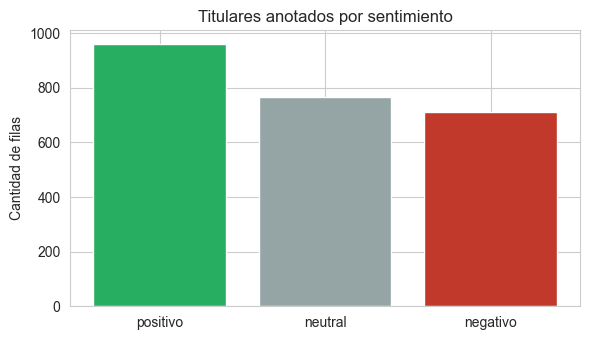

In [4]:
conteo = titulares["sentimiento"].value_counts()
print(conteo)
print()
print(conteo.div(conteo.sum()).round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
ax.set_ylabel("Cantidad de filas")
ax.set_title("Titulares anotados por sentimiento")
plt.tight_layout()
plt.show()

**Clases bastante parejas** (29% negativo, 31% neutral, 39% positivo). No hace falta `class_weight`. Un modelo que dijera siempre "positivo" acertaría ~39% de las veces: ese es el piso a superar.

In [5]:
titulares["candidatos_por_titular"] = titulares.groupby("titulo")["candidato_anotado"].transform("count")

por_titular = titulares.drop_duplicates("titulo")["candidatos_por_titular"].value_counts().sort_index()
print("Titulares según cuántos candidatos mencionan:")
print(por_titular)

Titulares según cuántos candidatos mencionan:
candidatos_por_titular
1    1567
2     363
3      38
4       8
Name: count, dtype: int64


**Un 21% de los titulares (409) tienen más de un candidato**, y justamente esos son los que tienen etiquetas contradictorias. Un modelo que lee solo el texto no puede dar dos respuestas distintas para el mismo texto. Lo resolvemos en la sección 3.

In [6]:
for sentimiento in ["positivo", "negativo", "neutral"]:
    print(sentimiento.upper())
    muestra = titulares[titulares["sentimiento"] == sentimiento].sample(4, random_state=3)
    for _, fila in muestra.iterrows():
        print(f"  [{fila['candidato_anotado']}] {fila['titulo']}")
    print()

POSITIVO
  [Fernández] Junto con Cristina y los gobernadores, Fernández pidió fortalecer la unidad peronista
  [Alberto F] La carta de Alberto F. para diferenciarse de Cristina
  [Del Caño] Del Caño: “Es imposible seguir las políticas del FMI, pagar la deuda y decir que se está del lado de los intereses populares”
  [Macri] Macri aseguró que "no se va a resignar" y convocó a un "octubre histórico"

NEGATIVO
  [Macri] Axel Kicillof: “Macri no entendió lo que dijo la sociedad en las urnas, no le pidió hacer una caravana electoral y decir que sí se puede”
  [Macri] El debate presidencial transcurre con cruces entre Macri y Fernández
  [Juntos por el Cambio] Osvaldo quemó boletas de Juntos por el Cambio
  [Alberto Fernández] Alberto Fernández todavía no pasó el test de autoridad

NEUTRAL
  [Alberto Fernández] Alberto Fernández homenajeó a Righi, el incómodo símbolo judicial de los K
  [Macri] Posturas opuestas sobre el aborto legal, la carta que jugaron Macri y Alberto Fernández en la rect

**Comparemos con los datos sintéticos.** Acá no hay plantillas: nadie escribe "Fracaso del Gobierno:" para avisarte el tono. "Alberto Fernández todavía no pasó el test de autoridad" es negativo sin tener ninguna palabra fuerte, y `Macri aseguró que "no se va a resignar"` es positivo aunque tenga un "no". Y la frontera entre positivo y neutral es borrosa incluso para una persona.

Vamos a esperar un accuracy bastante más bajo que con los datos sintéticos, y eso está bien: es lo que pasa cuando el texto es de verdad.

---
## 3. Preparación

Cuatro decisiones, cada una con su porqué.

**1. Nos quedamos con los titulares de un solo candidato.** El modelo ve solo el texto. Si el mismo texto llega con dos etiquetas distintas (positivo para uno, negativo para otro), no hay forma de que aprenda algo coherente. Perdemos 409 titulares, pero los que quedan tienen una única respuesta correcta.

In [7]:
unico = titulares[titulares["candidatos_por_titular"] == 1].copy()

print(f"Titulares que quedan: {len(unico)}")

Titulares que quedan: 1567


**2. Agrupamos los nombres del candidato.** El dataset registra el nombre tal cual aparece en el titular: "Macri", "Mauricio Macri" y "Cambiemos" son la misma campaña, pero figuran como tres candidatos distintos. Los juntamos con una agrupación simple, a ojo, suficiente para este análisis.

In [8]:
def agrupar_candidato(nombre):
    nombre = nombre.lower()
    if "macri" in nombre or "cambiemos" in nombre or "juntos por el cambio" in nombre:
        return "Macri"
    if "cristina" in nombre:
        return "Cristina Kirchner"
    if "alberto" in nombre or "fernández" in nombre or "frente de todos" in nombre:
        return "Alberto Fernández"
    if "lavagna" in nombre:
        return "Lavagna"
    if "izquierda" in nombre or "fit" in nombre or "caño" in nombre:
        return "Izquierda"
    return "Otros"


unico["candidato"] = unico["candidato_anotado"].apply(agrupar_candidato)

print(unico["candidato"].value_counts())
print()
print("Cómo aparece 'Macri' escrito en los titulares:")
print(unico[unico["candidato"] == "Macri"]["candidato_anotado"].value_counts().head(5))

candidato
Macri                654
Alberto Fernández    471
Izquierda            174
Otros                107
Cristina Kirchner     92
Lavagna               69
Name: count, dtype: int64

Cómo aparece 'Macri' escrito en los titulares:
candidato_anotado
Macri                   379
Mauricio Macri          221
Cambiemos                32
Juntos por el Cambio     20
cambiemos                 1
Name: count, dtype: int64


**3. Enmascaramos el nombre del candidato.** Reemplazamos "Macri" por `CANDIDATO` en el texto que ve el modelo. Es lo mismo que hicieron los anotadores para no contaminarse con sus simpatías, y es el equivalente de dejar afuera la columna `medio` en el notebook sintético: si el modelo ve el nombre, aprende "Macri = negativo" (porque algunos medios hablan mal de Macri) y después nuestro ranking por candidato sería circular. Queremos que juzgue el **lenguaje** alrededor del candidato, no quién es.

In [9]:
def enmascarar(fila):
    return re.sub(re.escape(fila["candidato_anotado"]), "CANDIDATO", fila["titulo"], flags=re.IGNORECASE)


unico["titulo_enmascarado"] = unico.apply(enmascarar, axis=1)

for _, fila in unico.head(3).iterrows():
    print("Antes:  ", fila["titulo"])
    print("Después:", fila["titulo_enmascarado"])
    print()

Antes:   Barrio Aeroclub: la Izquierda propone urbanización y adjudicación de terrenos
Después: Barrio Aeroclub: CANDIDATO propone urbanización y adjudicación de terrenos

Antes:   Elecciones municipales: el #FITUnidad busca fortalecer la izquierda en la ciudad de Neuquén
Después: Elecciones municipales: el #FITUnidad busca fortalecer CANDIDATO en la ciudad de Neuquén

Antes:   [Videos] Mirá todos los spots del Frente de Izquierda Unidad en Mendoza
Después: [Videos] Mirá todos los spots del CANDIDATO en Mendoza



Probamos entrenar con y sin enmascarar: la diferencia en accuracy es de aproximadamente 1 punto. **Enmascarar casi no cuesta nada y nos saca de encima el problema de la circularidad.**

**4. Separamos train y test.** Los autores ya dejaron un `test` separado, y lo hicieron por noticia (el mismo titular nunca queda de los dos lados). Lo respetamos: entrenamos con `train` + `dev` (no vamos a ajustar hiperparámetros) y evaluamos con `test`, que el modelo nunca vio.

El resto de las decisiones son las mismas que con los datos sintéticos: no sacamos stopwords ("no gustó" vs "gustó"), no escalamos (son conteos; la Clase 05 con KNN sí lo necesitaba porque medía distancias) y usamos solo el texto como variable.

In [10]:
train = unico[unico["split"] != "test"]
test = unico[unico["split"] == "test"].copy()

X_train, y_train = train["titulo_enmascarado"], train["sentimiento"]
X_test, y_test = test["titulo_enmascarado"], test["sentimiento"]

print(f"Train: {len(X_train)} titulares | Test: {len(X_test)} titulares")

Train: 1175 titulares | Test: 392 titulares


---
## 4. Modelo

Mismo `Pipeline` que antes: bolsa de palabras y `MultinomialNB` con suavizado de Laplace (`alpha=1.0`). El vocabulario se arma solo con train, así que cualquier palabra que aparezca únicamente en test se ignora. Con titulares reales el vocabulario va a ser mucho más grande que con los sintéticos: la gente escribe de más maneras de las que podría escribir una plantilla.

In [11]:
modelo = Pipeline([
    ("bolsa_de_palabras", CountVectorizer()),
    ("naive_bayes", MultinomialNB(alpha=1.0)),
])

modelo.fit(X_train, y_train)

vocabulario = modelo.named_steps["bolsa_de_palabras"].get_feature_names_out()
print(f"Palabras que aprendió: {len(vocabulario)}")

Palabras que aprendió: 3244


**3.244 palabras con apenas 1.175 titulares** (en el notebook sintético eran 212). Es un problema típico del texto real: la mayoría de las palabras aparecen una o dos veces y el modelo casi no tiene evidencia sobre ellas. El suavizado de Laplace evita que den probabilidad cero, pero no les agrega información.

Probemos a mano con cuatro titulares inventados (usamos `CANDIDATO` porque así es como el modelo ve el texto):

In [12]:
titulares_nuevos = [
    "CANDIDATO fracasó en su intento de frenar la inflación",
    "CANDIDATO prometió generar empleo y dar apoyo a las pymes",
    "CANDIDATO viajará a Chile para reunirse con empresarios",
    "CANDIDATO no logró convencer en el debate",
]

probabilidades = pd.DataFrame(
    modelo.predict_proba(titulares_nuevos),
    columns=modelo.classes_,
    index=titulares_nuevos,
).round(2)
probabilidades["predicción"] = modelo.predict(titulares_nuevos)
probabilidades

,negativo,neutral,positivo,predicción
CANDIDATO fracasó en su intento de frenar la inflación,0.12,0.58,0.30,neutral
CANDIDATO prometió generar empleo y dar apoyo a las pymes,0.00,0.00,1.00,positivo
CANDIDATO viajará a Chile para reunirse con empresarios,0.02,0.74,0.24,neutral
CANDIDATO no logró convencer en el debate,0.09,0.24,0.67,positivo


**Dos fallas que vale la pena entender:**

- *"CANDIDATO fracasó en su intento de frenar la inflación"* sale **neutral**, no negativo. La palabra clave, *fracasó*, **nunca apareció en el entrenamiento**, así que el modelo la ignora (es el "chupete" de la teoría). Y no hay lematización: *fracasó* y *fracasaron* son para él dos palabras distintas.
- *"CANDIDATO no logró convencer en el debate"* sale **positivo** (67%) y negativo apenas 9%. *no* reparte casi parejo entre las tres clases (36% / 29% / 34%): no invierte nada. *logró* incluso tira un poco hacia negativo, pero apareció solo 2 veces, y *convencer* tira hacia positivo. Con el peso a priori de la clase positiva (42%), gana positivo. Naive Bayes suma señales palabra por palabra: no entiende que "no logró" es lo opuesto de "logró".

Con datos sintéticos esto no pasaba, porque cada tono tenía sus propias palabras, repetidas muchas veces. Con texto real, la evidencia es mucho más escasa.

**Podés probar tus propios titulares** en `clasificador_titulares.html` (está en esta misma carpeta): escribís un titular y muestra el porcentaje de cada clase y cómo leyó cada palabra.

---
## 5. Evaluación

Con los titulares de test, comparado contra el piso de "decir siempre la clase más frecuente".

In [13]:
y_pred = modelo.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
piso = y_test.value_counts(normalize=True).max()

print(f"Accuracy del modelo:           {accuracy:.1%}")
print(f"Piso (siempre la mayoritaria): {piso:.1%}")

Accuracy del modelo:           60.7%
Piso (siempre la mayoritaria): 41.1%


In [14]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negativo       0.72      0.41      0.52       116
     neutral       0.54      0.50      0.52       115
    positivo       0.61      0.83      0.70       161

    accuracy                           0.61       392
   macro avg       0.62      0.58      0.58       392
weighted avg       0.62      0.61      0.59       392


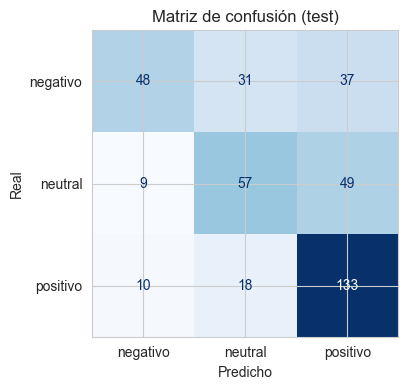

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Matriz de confusión (test)")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

**Lectura de negocio:**

- **61% contra un piso de 41%.** El modelo aprendió algo real, pero está lejos del 96% de los datos sintéticos. Es lo esperable: titulares reales, 1.175 para entrenar y tres personas que a veces no se ponen de acuerdo sobre qué es "positivo".
- **El modelo es optimista.** Acierta el 83% de los positivos pero solo el 41% de los negativos: 37 de 116 titulares negativos los lee como positivos. Se inclina por la clase más grande (42% del entrenamiento) y encuentra menos palabras claras para el tono negativo.
- **Ese es el error caro para el cliente:** una campaña que cree tener mejor cobertura de la que realmente tiene. Veamos qué titulares son.

In [16]:
test["prediccion"] = y_pred

graves = test[(test["sentimiento"] == "negativo") & (test["prediccion"] == "positivo")]
print(f"Titulares negativos que el modelo leyó como positivos: {len(graves)}")
print()
for _, fila in graves.sample(6, random_state=0).iterrows():
    print(f"- [{fila['candidato']}] {fila['titulo']}")

Titulares negativos que el modelo leyó como positivos: 37

- [Macri] Macri reparte entre los gremios un 10% de lo que reclaman para obras sociales
- [Alberto Fernández] Luego de apoyar a Alberto Fernández, Benjamín Vicuña recibió un fuerte ataque en las redes
- [Alberto Fernández] Huega de pilotos: el presidente de Aerolíneas habló de un "paro K" y criticó a Alberto Fernández
- [Macri] Los éxitos del ingeniero Macri: obras paralizadas y cientos de obreros despedidos
- [Alberto Fernández] Un absurdo para presionar a Alberto Fernández que inquieta a la propia industria brasileña
- [Alberto Fernández] El campo, contra las propuestas que el PJ le entregó a Alberto Fernández: “Son recetas que fracasaron”


**¿Por qué los leyó como positivos?**

- **Le faltan las palabras clave.** Casi todos tienen palabras que a una persona le delatan el tono, pero que el modelo **nunca vio en el entrenamiento** y por eso ignora: *absurdo*, *presionar*, *inquieta*; *recetas*, *fracasaron*; *paralizadas*, *despedidos*, y hasta *éxitos* en "Los éxitos del ingeniero Macri: obras paralizadas...", que además es ironía. Decide con las palabras comunes que le quedan, que tiran hacia la clase más grande: positivo.
- **Algunas palabras que sí conoce tiran para el lado inesperado.** En "Luego de apoyar a Alberto Fernández, Benjamín Vicuña recibió un fuerte ataque...", *fuerte* (64% positiva) y *ataque* (51% positiva) pesan hacia positivo. Probablemente porque en este dataset el tono es sobre el candidato, y los titulares donde un candidato "ataca" a otro suelen ser positivos para el que ataca.
- **A veces duda de verdad.** En el titular de la huelga de pilotos el reparto es 47% negativo contra 50% positivo: *criticó* tira fuerte hacia negativo, pero el resto lo compensa.

**Para llevarse:** el cuello de botella no es el algoritmo, es el vocabulario. Con 1.175 titulares de entrenamiento, el modelo conoce pocas palabras de tono negativo. Más titulares etiquetados valdrían más que cualquier ajuste de `alpha`.

---
## 6. ¿Qué aprendió el modelo?

Igual que antes: para cada palabra, cuánto más probable es en titulares positivos que en negativos. Con datos reales hay palabras que aparecen una o dos veces y dan sesgos exagerados por pura casualidad, así que nos quedamos solo con las que se vieron al menos 10 veces en el entrenamiento.

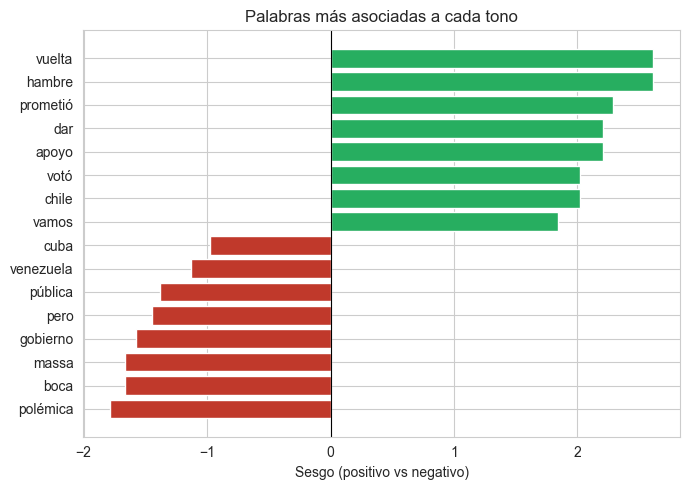

Palabras con al menos 10 apariciones: 144


In [17]:
log_prob = modelo.named_steps["naive_bayes"].feature_log_prob_
clases = list(modelo.classes_)

conteos = modelo.named_steps["bolsa_de_palabras"].transform(X_train).sum(axis=0)
frecuencia = pd.Series(np.asarray(conteos).ravel(), index=vocabulario)

sesgo = pd.Series(
    log_prob[clases.index("positivo")] - log_prob[clases.index("negativo")],
    index=vocabulario,
)
sesgo = sesgo[frecuencia >= 10].sort_values()

extremos = pd.concat([sesgo.head(8), sesgo.tail(8)])

colores = []
for valor in extremos.values:
    if valor > 0:
        colores.append(COLORES["positivo"])
    else:
        colores.append(COLORES["negativo"])

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(extremos.index, extremos.values, color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Sesgo (positivo vs negativo)")
ax.set_title("Palabras más asociadas a cada tono")
plt.tight_layout()
plt.show()

print(f"Palabras con al menos 10 apariciones: {len(sesgo)}")

**Qué mirar:**

- **Hay señal con sentido.** *prometió*, *apoyo*, *vamos*, *dar* (lenguaje de campaña) del lado positivo; *polémica* y *pero* del lado negativo.
- **Y hay ruido que parece señal.** *hambre* es la palabra más positiva y no porque el hambre sea buena noticia. Veamos por qué:

In [18]:
con_hambre = unico[(unico["split"] != "test") & unico["titulo"].str.lower().str.contains("hambre")]

print(con_hambre["sentimiento"].value_counts())
print()
for titulo in con_hambre["titulo"].head(3):
    print("-", titulo)

sentimiento
positivo    17
Name: count, dtype: int64

- Alberto Fernández lanzará la semana próxima su plan contra el hambre: convocará a empresarios, la Iglesia y movimientos sociales
- En qué consiste el plan que anunciará Alberto Fernández para combatir el hambre
- Alberto Fernández lanza "Argentina sin hambre" junto a 200 personalidades


**Las 17 son positivas y son todas del mismo plan, "Argentina sin hambre", de Alberto Fernández.** El modelo aprendió **una noticia**, no un tono. Con pocos datos, cualquier hecho que se repite en muchos titulares se convierte en "palabra de sentimiento".

- *massa* del lado negativo no es que Massa sea negativo: en varios titulares es la voz que critica a otros ("es un voto perdido").
- *cuba* y *boca* también figuran del lado negativo, pero son casi siempre neutrales (9 de 10 y 8 de 11). Este gráfico compara solo positivo contra negativo, así que una palabra neutral que nunca aparece en titulares positivos igual cae del lado negativo.
- Solo 144 de las 3.244 palabras se vieron al menos 10 veces: el modelo se apoya en muy pocas.

**Para llevarse:** con datos reales conviene mirar qué aprendió antes de confiar. Si solo miráramos el accuracy, no veríamos que parte de lo que "sabe" son noticias puntuales de 2019.

---
## 7. Aplicación: la cobertura por candidato

En un caso real, usaríamos el modelo sobre titulares que nadie anotó. Acá vamos a hacer un **simulacro**: tratamos el test como si no tuviera etiquetas, le pedimos al modelo la cobertura por candidato, y después la comparamos con la real. Es una forma de ver cuánto podríamos confiar en el modelo si no tuviéramos la respuesta.

In [19]:
real = pd.crosstab(test["candidato"], test["sentimiento"], normalize="index").mul(100)
predicho = pd.crosstab(test["candidato"], test["prediccion"], normalize="index").mul(100)

comparacion = pd.DataFrame({
    "titulares": test["candidato"].value_counts(),
    "% positivo real": real["positivo"],
    "% positivo predicho": predicho["positivo"],
    "% negativo real": real["negativo"],
    "% negativo predicho": predicho["negativo"],
}).round(0).sort_values("titulares", ascending=False)

comparacion

,titulares,% positivo real,% positivo predicho,% negativo real,% negativo predicho
candidato,,,,,
Macri,168,34.0,51.0,40.0,23.0
Alberto Fernández,105,44.0,58.0,22.0,9.0
Izquierda,51,67.0,73.0,2.0,4.0
Otros,34,18.0,47.0,53.0,32.0
Lavagna,19,74.0,68.0,11.0,11.0
Cristina Kirchner,15,27.0,40.0,33.0,33.0


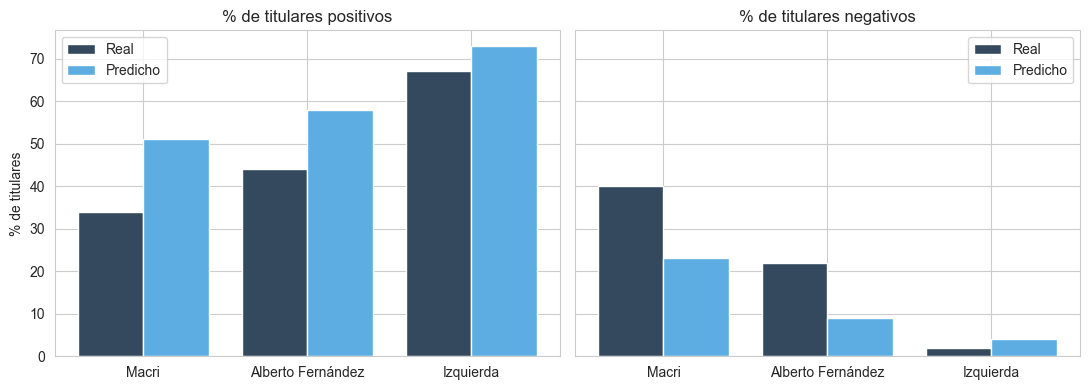

In [20]:
principales = ["Macri", "Alberto Fernández", "Izquierda"]
datos = comparacion.loc[principales]
posiciones = np.arange(len(principales))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

ax1.bar(posiciones - 0.2, datos["% positivo real"], width=0.4, color="#34495E", label="Real")
ax1.bar(posiciones + 0.2, datos["% positivo predicho"], width=0.4, color="#5DADE2", label="Predicho")
ax1.set_title("% de titulares positivos")
ax1.set_xticks(posiciones)
ax1.set_xticklabels(principales)
ax1.set_ylabel("% de titulares")
ax1.legend()

ax2.bar(posiciones - 0.2, datos["% negativo real"], width=0.4, color="#34495E", label="Real")
ax2.bar(posiciones + 0.2, datos["% negativo predicho"], width=0.4, color="#5DADE2", label="Predicho")
ax2.set_title("% de titulares negativos")
ax2.set_xticks(posiciones)
ax2.set_xticklabels(principales)
ax2.legend()

plt.tight_layout()
plt.show()

**Qué se sostiene y qué no:**

- **El orden se sostiene.** Tanto en lo real como en lo predicho, Alberto Fernández tiene más titulares positivos que Macri (44% vs 34% real; 58% vs 51% predicho) y Macri más negativos (40% vs 22% real; 23% vs 9% predicho). La Izquierda lidera en positivos.
- **Los números no se sostienen.** El modelo es optimista de forma sistemática: sobrestima lo positivo en 14 a 17 puntos y subestima lo negativo en 13 a 17 puntos para los dos candidatos principales. Si le dijéramos al cliente "Macri tiene 23% de cobertura negativa", nos estaríamos quedando 17 puntos cortos (real: 40%).
- **Cuidado con las diferencias chicas.** Con 105 y 168 titulares, una diferencia de 7 a 10 puntos entre candidatos está en el límite del ruido estadístico. En el notebook sintético las diferencias entre medios eran de decenas de puntos; acá no.
- **Dos límites del análisis.** Sacamos los titulares con más de un candidato, que son justo los cruces Macri contra Fernández: la cobertura "mano a mano" quedó afuera. Y el dataset no trae el **medio**, así que no sabemos quién escribe cada titular. Eso importa: la Izquierda tiene 67% de positivos, y una hipótesis es que muchos de esos titulares los publican medios de la propia izquierda. El dataset no nos deja verificarlo.

---
## 8. Cierre

**Qué nos llevamos:**

1. **Con datos reales el modelo rinde bastante peor que con datos sintéticos** (61% contra 96%), y es la lección más importante del ejercicio. Los datos sintéticos tienen plantillas; los reales tienen ironía, negaciones, contexto y anotadores que discrepan.
2. **El ranking sobrevive, los porcentajes no.** Sirve para ordenar candidatos, no para reportarle cifras exactas al cliente.
3. **Aprende temas y noticias, no solo tono** (el caso *hambre*). Con pocos datos, cualquier noticia que se repite se vuelve una "palabra de sentimiento".
4. **Preparar los datos pesó tanto como elegir el modelo.** Decidir qué hacer con los titulares de varios candidatos y enmascarar el nombre fue lo que hizo válido el análisis.

**Para probar en casa:**

- Sacar los neutrales y quedarse con positivo contra negativo. En nuestra prueba el accuracy sube a ~76% contra un piso de 58%. ¿Por qué creen que mejora?
- `CountVectorizer(ngram_range=(1, 2))` para mirar pares de palabras ("no logró"). En nuestra prueba no mejora. ¿Por qué creen que no? (Pista: ya teníamos 3.244 palabras para 1.175 titulares.)
- Cambiar `alpha`. ¿Qué pasa con las palabras que se vieron una sola vez?
- Pensar qué dato nos faltaría para responder la pregunta original, "¿qué medios?".

**Gancho a la Clase 11:** hoy teníamos titulares con etiqueta, y etiquetar fue lo caro. ¿Y si no tuviéramos ninguna? Con **clustering** vamos a ver cómo agrupar datos por parecido sin que nadie los haya etiquetado antes.